# IMDB Sentiment Classifier
Fine-tuning BERT for binary sentiment classification, compared against a TF-IDF + Logistic Regression baseline, with a Gradio demo.

**Runtime:** Runtime > Change runtime type > T4 GPU. If Colab asks you to restart after the install cell, restart and run everything from the top.

## Setup

In [1]:
!pip install -q -U transformers datasets accelerate scikit-learn gradio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    set_seed,
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available")

GPU: Tesla T4


## Load the dataset

In [3]:
dataset = load_dataset("stanfordnlp/imdb")
print(dataset)

sample = dataset["train"][0]
print("\nLabel:", sample["label"], "(0 = negative, 1 = positive)")
print("Review:", sample["text"][:300], "...")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Label: 0 (0 = negative, 1 = positive)
Review: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h ...


The test set comes from IMDB's separate `test` split. Sampling it from the train split (as in the original version) lets the model see test reviews during training and inflates the scores.

Train: 3600 | Val: 400 | Test: 1000


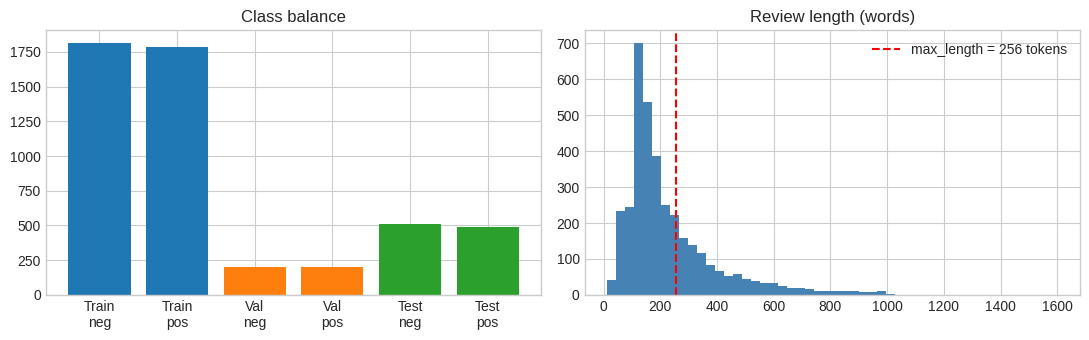

In [4]:
TRAIN_SIZE = 4000
TEST_SIZE = 1000

full_train = dataset["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
test_ds = dataset["test"].shuffle(seed=SEED).select(range(TEST_SIZE))

split = full_train.train_test_split(test_size=0.1, seed=SEED, stratify_by_column="label")
train_ds, val_ds = split["train"], split["test"]

full_train_texts = list(full_train["text"])
full_train_labels = np.array(list(full_train["label"]))
test_texts = list(test_ds["text"])
test_labels = np.array(list(test_ds["label"]))

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, ds in [("Train", train_ds), ("Val", val_ds), ("Test", test_ds)]:
    counts = np.bincount(np.array(list(ds["label"])), minlength=2)
    axes[0].bar([f"{name}\nneg", f"{name}\npos"], counts)
axes[0].set_title("Class balance")

lengths = [len(t.split()) for t in train_ds["text"]]
axes[1].hist(lengths, bins=50, color="steelblue")
axes[1].axvline(256, color="red", linestyle="--", label="max_length = 256 tokens")
axes[1].set_title("Review length (words)")
axes[1].legend()
plt.tight_layout()
plt.show()

## Baseline: TF-IDF + Logistic Regression
A simple reference point to check that BERT is worth the extra cost.

In [5]:
tfidf = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), stop_words="english")
X_train = tfidf.fit_transform(full_train_texts)
X_test = tfidf.transform(test_texts)

baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train, full_train_labels)
base_preds = baseline.predict(X_test)

baseline_acc = accuracy_score(test_labels, base_preds)
baseline_f1 = f1_score(test_labels, base_preds)
print(f"Baseline  accuracy: {baseline_acc:.4f} | f1: {baseline_f1:.4f}")

Baseline  accuracy: 0.8410 | f1: 0.8402


## Tokenize

In [6]:
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

train_tok = train_ds.map(tokenize, batched=True)
val_tok = val_ds.map(tokenize, batched=True)
test_tok = test_ds.map(tokenize, batched=True)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/3600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

## Model, metrics and trainer

In [7]:
id2label = {0: "negative", 1: "positive"}
label2id = {v: k for k, v in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred.predictions, eval_pred.label_ids
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds),
    }

EPOCHS = 3
BATCH_SIZE = 16
total_steps = (len(train_tok) // BATCH_SIZE) * EPOCHS
warmup_steps = int(0.1 * total_steps)

training_args = TrainingArguments(
    output_dir="./bert_imdb_output",
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    learning_rate=2e-5,
    warmup_steps=warmup_steps,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
    logging_steps=25,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Fine-tune

In [8]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.346858,0.422480,0.830000,0.803468
2,0.215464,0.316545,0.880000,0.880597
3,0.073643,0.430964,0.897500,0.898765


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=675, training_loss=0.2620135250797978, metrics={'train_runtime': 175.5589, 'train_samples_per_second': 61.518, 'train_steps_per_second': 3.845, 'total_flos': 1420799698944000.0, 'train_loss': 0.2620135250797978, 'epoch': 3.0})

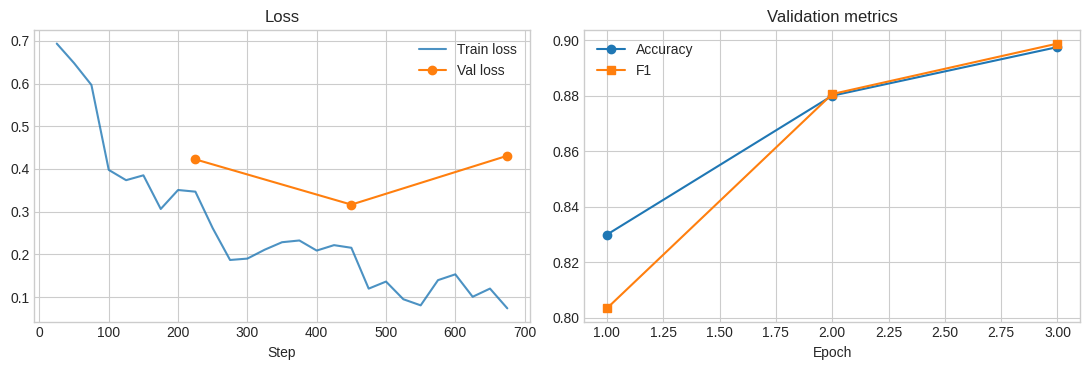

In [9]:
log = trainer.state.log_history
train_loss = [(l["step"], l["loss"]) for l in log if "loss" in l]
evals = [l for l in log if "eval_loss" in l]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

if train_loss:
    axes[0].plot(*zip(*train_loss), label="Train loss", alpha=0.8)
axes[0].plot([e["step"] for e in evals], [e["eval_loss"] for e in evals],
             "o-", label="Val loss")
axes[0].set_xlabel("Step")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot([e["epoch"] for e in evals], [e["eval_accuracy"] for e in evals],
             "o-", label="Accuracy")
axes[1].plot([e["epoch"] for e in evals], [e["eval_f1"] for e in evals],
             "s-", label="F1")
axes[1].set_xlabel("Epoch")
axes[1].set_title("Validation metrics")
axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluate on the test set

In [10]:
output = trainer.predict(test_tok)
logits = np.asarray(output.predictions)
labels = np.asarray(output.label_ids)
preds = logits.argmax(axis=1)

shifted = np.exp(logits - logits.max(axis=1, keepdims=True))
probs = shifted / shifted.sum(axis=1, keepdims=True)
confidence = probs.max(axis=1)

bert_acc = accuracy_score(labels, preds)
bert_f1 = f1_score(labels, preds)
print(f"BERT accuracy: {bert_acc:.4f} | f1: {bert_f1:.4f}\n")
print(classification_report(labels, preds, target_names=["negative", "positive"], digits=4))

BERT accuracy: 0.8850 | f1: 0.8849

              precision    recall  f1-score   support

    negative     0.9059    0.8652    0.8851       512
    positive     0.8650    0.9057    0.8849       488

    accuracy                         0.8850      1000
   macro avg     0.8855    0.8855    0.8850      1000
weighted avg     0.8859    0.8850    0.8850      1000



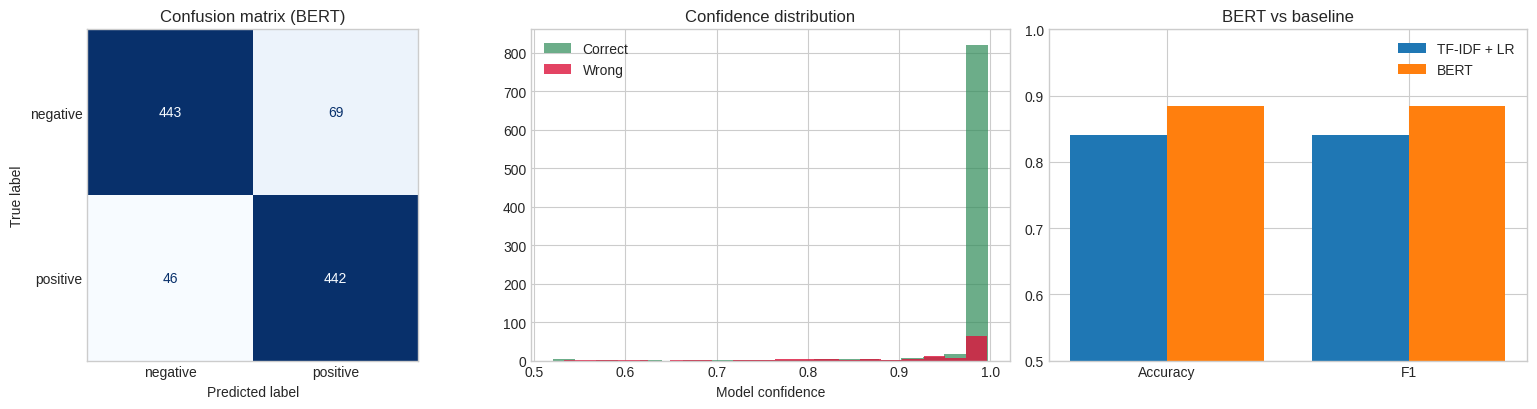

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ConfusionMatrixDisplay.from_predictions(
    labels, preds, display_labels=["negative", "positive"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion matrix (BERT)")
axes[0].grid(False)

correct = preds == labels
axes[1].hist(confidence[correct], bins=20, alpha=0.7, label="Correct", color="seagreen")
axes[1].hist(confidence[~correct], bins=20, alpha=0.8, label="Wrong", color="crimson")
axes[1].set_xlabel("Model confidence")
axes[1].set_title("Confidence distribution")
axes[1].legend()

x = np.arange(2)
axes[2].bar(x - 0.2, [baseline_acc, baseline_f1], 0.4, label="TF-IDF + LR")
axes[2].bar(x + 0.2, [bert_acc, bert_f1], 0.4, label="BERT")
axes[2].set_xticks(x)
axes[2].set_xticklabels(["Accuracy", "F1"])
axes[2].set_ylim(0.5, 1.0)
axes[2].set_title("BERT vs baseline")
axes[2].legend()

plt.tight_layout()
plt.show()

### Most confident mistakes

In [12]:
wrong_idx = np.where(~correct)[0]
worst = wrong_idx[np.argsort(-confidence[wrong_idx])][:5]

for i in worst:
    print(f"True: {id2label[labels[i]]:8s} | Predicted: {id2label[preds[i]]:8s} | Conf: {confidence[i]:.2%}")
    print(test_texts[i][:300], "...\n")

True: negative | Predicted: positive | Conf: 99.63%
Purchased this film for one dollar and figured I could never go wrong, my big mistake was watching it. Enjoyed the acting of Ice-T and the rapping which gave lots of class to this film about Los Angeles and the world of pimps. There is a boxer who kills one of his opponents in a practice ring and wh ...

True: negative | Predicted: positive | Conf: 99.62%
Going into the movie with the right expectations, I somewhat liked this movie. Like most reviewers who have seen this movie, I fully agree that the plot was razor thin, clichéd, and I could predict every plot twist from the very beginning of the movie. But, the dancing sequences were VERY well done, ...

True: negative | Predicted: positive | Conf: 99.61%
Ha ha. - oh no - what to say about this film? Yes - green eggs and ham makes more sense than this movie. Where does one start? A lot of the good stuff has already been said - so I won't divulge into the same territory. I believe you

## Predict on new reviews

In [13]:
def predict_proba(text):
    model.eval()
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                       max_length=MAX_LENGTH).to(model.device)
    with torch.no_grad():
        logits = model(**inputs).logits
    p = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    return {id2label[i]: float(p[i]) for i in range(2)}

reviews = [
    "This movie was absolutely fantastic. Brilliant acting and a gripping story.",
    "I hated this film. It was boring, too long, and badly written.",
    "It was okay, some good moments, but overall forgettable.",
]

for r in reviews:
    p = predict_proba(r)
    label = max(p, key=p.get)
    print(f"{label:8s} ({p[label]:.2%}) -> {r[:60]}...")

positive (99.59%) -> This movie was absolutely fantastic. Brilliant acting and a ...
negative (99.07%) -> I hated this film. It was boring, too long, and badly writte...
negative (69.25%) -> It was okay, some good moments, but overall forgettable....


## Save model and tokenizer

In [14]:
SAVE_DIR = "./imdb_bert"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Saved to:", SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: ./imdb_bert


## Gradio demo

In [15]:
import gradio as gr

device = "cuda" if torch.cuda.is_available() else "cpu"
demo_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
demo_model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to(device).eval()

def classify_review(review):
    if not review or not review.strip():
        return {}
    inputs = demo_tokenizer(review, return_tensors="pt", truncation=True,
                            max_length=MAX_LENGTH).to(device)
    with torch.no_grad():
        p = torch.softmax(demo_model(**inputs).logits, dim=-1)[0].cpu().numpy()
    return {id2label[i]: float(p[i]) for i in range(2)}

demo = gr.Interface(
    fn=classify_review,
    inputs=gr.Textbox(lines=5, placeholder="Type a movie review here...", label="Movie review"),
    outputs=gr.Label(num_top_classes=2, label="Prediction"),
    title="IMDB Sentiment Classifier",
    description="Fine-tuned BERT that predicts whether a movie review is positive or negative.",
    flagging_mode="never",
    examples=[[r] for r in reviews],
)

demo.launch(share=True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5ac0321c44bf0dd005.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
